# QFire Cusco — Fase 02: EDA geoespacial y red vial

**Objetivo:** representar el historial de Cusco y preparar conexiones por carretera entre un acopio y puntos receptores de recursos. El producto de esta fase es una red vial versionada, puntos asociados a ella y matrices de costos. La asignación de donaciones y el plan de reparto se construirán en las fases siguientes.

**Se mantienen dos niveles distintos:**

- **Historial territorial:** los 3.363 registros aptos para iniciar EDA, de las 13 provincias de Cusco, provenientes de la fase 01. No son incendios actualmente activos ni incidentes simultáneos.
- **Escenario logístico demostrativo:** un acopio y tres receptores simulados y configurables. Las ubicaciones receptoras son distintas de las coordenadas del incendio y no se presentan como puntos seguros acreditados.

La red vial procede de OpenStreetMap, extraída de la descarga de Perú de Geofabrik. El paquete incluye el extracto necesario y el grafo guardado para poder recalcular sin consultar un servidor de rutas en cada ejecución.

## Entradas y salidas

| Tipo | Archivo | Contenido |
|---|---|---|
| Entrada | `data/processed/incendios_para_mapeo.csv` | Historial utilizable de la fase 01 |
| Configuración | `config/puntos_logisticos_demo.csv` | Acopio y receptores simulados editables |
| Configuración | `config/phase2.json` | Área, umbral y supuestos de velocidad |
| Fuente vial | `data/raw/osm_vias_demo.osm` | Extracto de vías de OpenStreetMap |
| Salida | `data/geo/red_vial_escenario.graphml.gz` | Grafo vial dirigido versionado |
| Salida | `data/geo/tramos_viales.geojson.gz` | Geometrías e identificadores de todos los arcos |
| Salida | `data/geo/puntos_logisticos.csv` | Puntos y nodo vial asociado |
| Salida | `data/optimization/distance_matrix.csv` | Km de los caminos elegidos por tiempo estimado |
| Salida | `data/optimization/duration_matrix.csv` | Minutos de esos mismos caminos |
| Salida | `data/optimization/reachability_matrix.csv` | Conectividad dirigida |
| Visual | `outputs/maps/02_historial_y_logistica.html` | Mapa interactivo del historial y del escenario |

Los archivos `.gz` están comprimidos para mantener tamaños adecuados para GitHub. El código los lee automáticamente. No se usan distancias rectas como costos de transporte.

In [1]:
from pathlib import Path
import gzip
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import networkx as nx
import osmnx as ox
from IPython.display import display, IFrame, FileLink

def locate_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / 'src/qfire_cusco/geospatial.py').is_file() and (candidate / 'config/phase2.json').is_file():
            return candidate
    raise FileNotFoundError('Abra la carpeta completa qfire-cusco actualizada, con src, config y data.')

ROOT = locate_project_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from qfire_cusco.geospatial import (
    read_history, load_logistic_points, bbox_for_points, prepare_network,
    snap_points, build_costs, export_phase2, network_fingerprint,
)

pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 70)
FIGURES_DIR = ROOT / 'outputs/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Lectura y alcance del historial

La entrada se toma de la salida de la fase 01, no de un CSV con rutas de la computadora de otra persona. Se comprueban los IDs, el departamento, el rango temporal y los controles de mapeo.

Los dos registros sin confirmación permanecen en `incendios_historicos.csv`, pero no forman parte de esta preselección. Tampoco se transforma una fecha de término faltante en un incendio todavía activo.

In [2]:
history = read_history(ROOT)
print(f'Registros para EDA: {len(history):,}')
print(f'Provincias representadas: {history.PROVINCIA.nunique()}')
print(f'Última fecha presente: {history.FECHA_INICIO.max()}')
province_year = history.groupby(['PROVINCIA', 'ANIO']).size().unstack(fill_value=0)
display(province_year)

Registros para EDA: 3,363
Provincias representadas: 13
Última fecha presente: 2026-08-26


ANIO,2022,2023,2024,2025,2026
PROVINCIA,,,,,
ACOMAYO,54,18,19,14,0
ANTA,141,33,55,73,6
CALCA,90,40,38,26,9
CANAS,64,31,56,60,5
CANCHIS,87,19,48,45,8
CHUMBIVILCAS,191,73,84,145,8
CUSCO,37,15,17,27,6
ESPINAR,100,66,84,98,5
LA CONVENCION,209,155,129,93,27


## 2. Distribución geográfica de registros históricos

Este gráfico muestra coordenadas reportadas por año, con el historial completo del departamento. Es un resumen de registros, no un mapa de intensidad, predicción o magnitud de incendios. Las diferencias entre años también pueden reflejar cobertura y calidad del reporte.

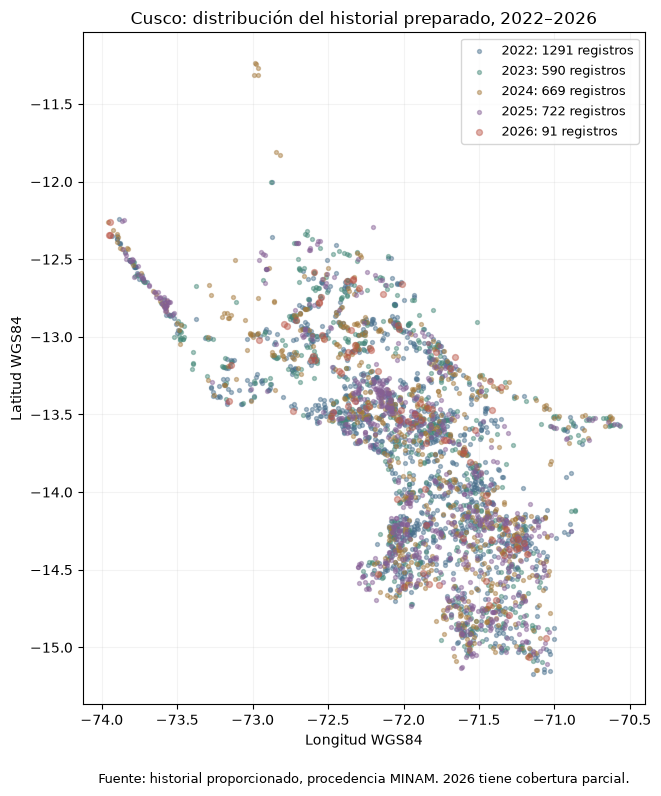

In [3]:
fig, ax = plt.subplots(figsize=(9, 8))
palette = {2022: '#486f8c', 2023: '#448878', 2024: '#a4793b', 2025: '#855f95', 2026: '#ba5446'}
for year, frame in history.groupby('ANIO'):
    ax.scatter(frame.LONGITUD, frame.LATITUD, s=8 if year != 2026 else 18, alpha=0.45,
               c=palette.get(int(year), "#6d7885"), label=f'{year}: {len(frame)} registros')
ax.set_aspect(1 / np.cos(np.deg2rad(history.LATITUD.median())))
ax.set_xlabel('Longitud WGS84')
ax.set_ylabel('Latitud WGS84')
ax.set_title('Cusco: distribución del historial preparado, 2022–2026')
ax.legend(frameon=True, fontsize=9)
ax.grid(alpha=0.15)
fig.text(0.5, 0.015, 'Fuente: historial proporcionado, procedencia MINAM. 2026 tiene cobertura parcial.', ha='center', fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
HISTORY_FIGURE = FIGURES_DIR / '02_historial_geoespacial.png'
fig.savefig(HISTORY_FIGURE, dpi=150, bbox_inches='tight')
plt.show()

## 3. Configuración del escenario logístico

Se trabaja inicialmente con `DEMO_CUSCO_001`: un acopio demostrativo en Cusco y tres receptores demostrativos en Anta, Urubamba y Calca, vinculados a registros históricos. La selección sirve para comprobar el flujo de datos y la conectividad; no reduce el alcance del historial a esas provincias.

**Para cambiar los puntos**, editar `config/puntos_logisticos_demo.csv`. Los ID de incidentes deben existir en el historial; las ubicaciones receptoras se indican explícitamente. No se copia automáticamente la coordenada del fuego como destino de un camión.

La columna `ORIGEN` identifica las ubicaciones simuladas y `VALIDADO_OPERATIVAMENTE` permanece en falso. Una dirección real de recepción puede sustituirse cuando se disponga de esa información.

In [4]:
config = json.loads((ROOT / 'config/phase2.json').read_text())
ALLOW_DOWNLOAD = False  # El escenario incluido puede ejecutarse con los archivos locales.
points = load_logistic_points(ROOT, history, config)
display(points[['PUNTO_ID', 'TIPO', 'NOMBRE', 'INCENDIO_ID', 'ORIGEN', 'VALIDADO_OPERATIVAMENTE']])
bbox = bbox_for_points(points, config['margen_grados'])
print('Área vial del escenario (oeste, sur, este, norte):', bbox)

,PUNTO_ID,TIPO,NOMBRE,INCENDIO_ID,ORIGEN,VALIDADO_OPERATIVAMENTE
0,AC01,ACOPIO,Acopio demostrativo Cusco,,SIMULADO,False
1,RE01,RECEPCION,Recepción demostrativa Anta,MINAM-109595,SIMULADO,False
2,RE02,RECEPCION,Recepción demostrativa Urubamba,MINAM-109603,SIMULADO,False
3,RE03,RECEPCION,Recepción demostrativa Calca,MINAM-109594,SIMULADO,False


Área vial del escenario (oeste, sur, este, norte): (-72.228, -13.6026, -71.875, -13.224)


## 4. Red vial real y trazabilidad

El grafo conserva sentidos de circulación y componentes desconectados. Cada arco tiene un identificador `u_v_key`, geometría y versión de red. Esto permitirá identificar los tramos que se bloquearán en la fase 06.

El paquete guarda una red para el área requerida por los puntos del escenario, con margen para conexiones. No contiene la red vial de todo el departamento. Para un escenario en otra zona se cambia la configuración y se amplía el extracto; el programa rechaza reutilizar silenciosamente una cobertura insuficiente.

Se prioriza el grafo local. Si es necesario reconstruirlo, se utiliza el extracto OSM incluido. `ALLOW_DOWNLOAD=True` habilita la consulta a Overpass para otra cobertura cuando el servidor esté disponible. La alternativa documentada es generar un extracto desde un PBF de Geofabrik con `scripts/build_osm_extract.py`.

In [5]:
graph, network_manifest, network_mode = prepare_network(ROOT, points, config, allow_download=ALLOW_DOWNLOAD)
print('Modo de carga:', network_mode)
print('Nodos:', graph.number_of_nodes())
print('Arcos dirigidos:', graph.number_of_edges())
print('Componentes débiles:', nx.number_weakly_connected_components(graph))
print('Versión de red:', network_manifest['red_version'])
print('Fuente:', network_manifest['provenance'].get('url', 'ver manifiesto'))
assert network_fingerprint(graph) == network_manifest['red_version']

Modo de carga: CACHE
Nodos: 17812
Arcos dirigidos: 46542
Componentes débiles: 51
Versión de red: f894db79e4b393373fb7
Fuente: https://download.geofabrik.de/south-america/peru-latest.osm.pbf


## 5. Tiempos estimados y asociación de puntos a la red

Las longitudes provienen de las vías de OSM. Los tiempos se estiman con velocidades declaradas por clase y, cuando una etiqueta `maxspeed` es interpretable, se usa el menor valor entre esa etiqueta y el supuesto de clase. **No son mediciones de tráfico ni velocidades garantizadas para un camión.**

Cada ubicación se asocia a un nodo vial y se calcula su separación en metros. El umbral de 300 m controla la calidad de esa asociación; no acredita un acceso físico seguro. Las matrices posteriores describen el trayecto entre nodos viales. El acceso final hasta la ubicación receptora sigue pendiente de validación y no se suma como una carretera ficticia.

In [6]:
speed_policy = pd.DataFrame(config['velocidades_supuesto_kph'].items(), columns=['CLASE_VIAL', 'VELOCIDAD_SUPUESTA_KPH'])
display(speed_policy)
snapped_points = snap_points(graph, points, config['max_snap_m'])
display(snapped_points[['PUNTO_ID', 'NODO_VIAL', 'DISTANCIA_A_NODO_M', 'SNAP_OK', 'ACCESO_ULTIMO_TRAMO_VALIDADO']])
if not snapped_points.SNAP_OK.all():
    raise ValueError('Revise los puntos cuyo nodo vial supera el umbral antes de construir matrices.')

,CLASE_VIAL,VELOCIDAD_SUPUESTA_KPH
0,motorway,70
1,motorway_link,40
2,trunk,60
3,trunk_link,35
4,primary,50
5,primary_link,30
6,secondary,40
7,secondary_link,25
8,tertiary,35
9,tertiary_link,25


,PUNTO_ID,NODO_VIAL,DISTANCIA_A_NODO_M,SNAP_OK,ACCESO_ULTIMO_TRAMO_VALIDADO
0,AC01,3738278170,33.949002,True,False
1,RE01,2794346820,44.349443,True,False
2,RE02,114606257,15.224360,True,False
3,RE03,1670405721,49.447666,True,False


## 6. Costos por carretera y conectividad dirigida

Se elige el camino de **menor tiempo estimado** y se calculan tanto su duración como sus kilómetros. Ambas matrices describen el mismo recorrido. Viajar de A a B puede tener un costo distinto de B a A.

La distancia geodésica entre nodos se calcula únicamente como control descriptivo. Un par sin conexión se guarda con `ALCANZABLE=False` y costo infinito; no se reemplaza por cero o por una línea recta.

Estas conexiones entre pares no constituyen todavía un plan de reparto: faltan el inventario, las solicitudes y los vehículos de la fase 03.

In [7]:
costs = build_costs(graph, snapped_points)
distance_matrix, duration_matrix, reachability_matrix, road_pairs, route_features = costs
print('Kilómetros de los caminos elegidos por tiempo estimado:')
display(distance_matrix.round(2))
print('Duraciones estimadas en minutos:')
display(duration_matrix.round(1))
display(road_pairs.loc[road_pairs.ORIGEN.ne(road_pairs.DESTINO),
                       ['ORIGEN', 'DESTINO', 'ALCANZABLE', 'DISTANCIA_KM', 'DURACION_MIN', 'GEODESICA_NODOS_KM']].round(2))
assert np.allclose(np.diag(distance_matrix), 0)
assert np.allclose(np.diag(duration_matrix), 0)
assert distance_matrix.index.tolist() == snapped_points.PUNTO_ID.tolist()

Kilómetros de los caminos elegidos por tiempo estimado:


,AC01,RE01,RE02,RE03
PUNTO_ID,,,,
AC01,0.00,26.27,52.30,71.22
RE01,26.35,0.00,30.72,49.64
RE02,52.38,30.73,0.00,21.41
RE03,71.29,49.64,21.41,0.00


Duraciones estimadas en minutos:


,AC01,RE01,RE02,RE03
PUNTO_ID,,,,
AC01,0.0,27.3,59.8,78.3
RE01,27.4,0.0,36.0,54.6
RE02,59.9,36.1,0.0,22.9
RE03,78.4,54.6,22.8,0.0


,ORIGEN,DESTINO,ALCANZABLE,DISTANCIA_KM,DURACION_MIN,GEODESICA_NODOS_KM
1,AC01,RE01,True,26.27,27.34,20.34
2,AC01,RE02,True,52.30,59.75,28.84
3,AC01,RE03,True,71.22,78.29,22.34
4,RE01,AC01,True,26.35,27.42,20.34
6,RE01,RE02,True,30.72,36.02,17.39
7,RE01,RE03,True,49.64,54.56,25.73
8,RE02,AC01,True,52.38,59.93,28.84
9,RE02,RE01,True,30.73,36.12,17.39
11,RE02,RE03,True,21.41,22.85,17.56
12,RE03,AC01,True,71.29,78.37,22.34


## 7. Visualización vial del escenario

El mapa estático usa las geometrías reales de los tramos. Las conexiones mostradas van desde el acopio a cada receptor y siguen los caminos calculados sobre el grafo. Los símbolos marcan los nodos asociados a los puntos; no representan un incendio activo ni el despliegue de brigadas.

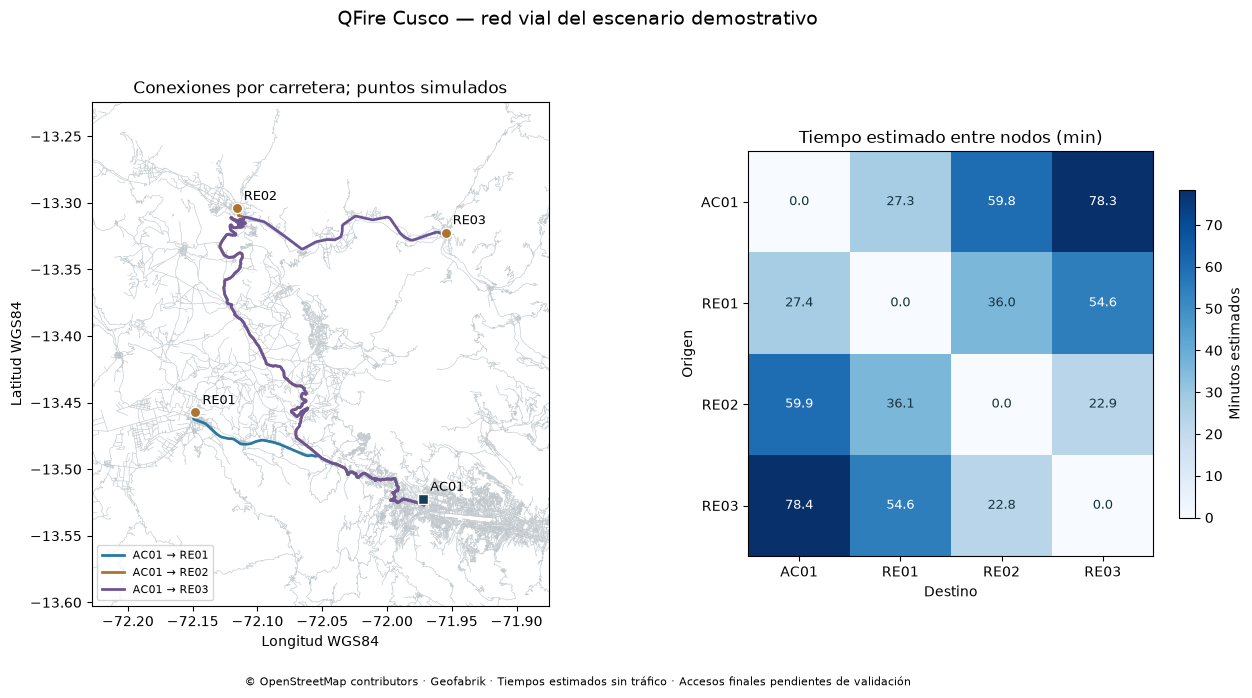

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1.6, 1]})
segments = [np.asarray(data['geometry'].coords) for _, _, _, data in graph.edges(keys=True, data=True)]
axes[0].add_collection(LineCollection(segments, colors='#bfc7cc', linewidths=0.35, alpha=0.7))
source_id = snapped_points.loc[snapped_points.TIPO.eq('ACOPIO'), 'PUNTO_ID'].iloc[0]
route_colors = ['#2878a3', '#ad7430', '#6b5597']
source_routes = [f for f in route_features['features'] if f['properties']['ORIGEN'] == source_id]
for i, feature in enumerate(source_routes):
    xy = np.asarray(feature['geometry']['coordinates'])
    axes[0].plot(xy[:, 0], xy[:, 1], color=route_colors[i % len(route_colors)], lw=2,
                 label=f"{source_id} → {feature['properties']['DESTINO']}")
for row in snapped_points.itertuples():
    axes[0].scatter(row.LONGITUD_NODO, row.LATITUD_NODO, s=55, marker='s' if row.TIPO == 'ACOPIO' else 'o',
                    c='#153e58' if row.TIPO == 'ACOPIO' else '#ad7430', edgecolors='white', zorder=5)
    axes[0].annotate(row.PUNTO_ID, (row.LONGITUD_NODO, row.LATITUD_NODO), xytext=(5, 6), textcoords='offset points', fontsize=9)
axes[0].set_xlim(bbox[0], bbox[2])
axes[0].set_ylim(bbox[1], bbox[3])
axes[0].set_aspect(1 / np.cos(np.deg2rad(snapped_points.LATITUD.mean())))
axes[0].set_xlabel('Longitud WGS84')
axes[0].set_ylabel('Latitud WGS84')
axes[0].set_title('Conexiones por carretera; puntos simulados')
axes[0].legend(loc='lower left', fontsize=8)
image = axes[1].imshow(duration_matrix.to_numpy(), cmap='Blues')
axes[1].set_xticks(range(len(duration_matrix)), duration_matrix.columns)
axes[1].set_yticks(range(len(duration_matrix)), duration_matrix.index)
axes[1].set_xlabel('Destino')
axes[1].set_ylabel('Origen')
axes[1].set_title('Tiempo estimado entre nodos (min)')
for i in range(len(duration_matrix)):
    for j in range(len(duration_matrix)):
        value = duration_matrix.iloc[i, j]
        axes[1].text(j, i, f'{value:.1f}' if np.isfinite(value) else 'Sin ruta', ha='center', va='center',
                     color='white' if value > duration_matrix.to_numpy().max() * 0.6 else '#18343f', fontsize=9)
fig.colorbar(image, ax=axes[1], shrink=0.65, label='Minutos estimados')
fig.suptitle('QFire Cusco — red vial del escenario demostrativo', fontsize=14)
fig.text(0.5, 0.015, '© OpenStreetMap contributors · Geofabrik · Tiempos estimados sin tráfico · Accesos finales pendientes de validación', ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.045, 1, 0.95])
ROAD_FIGURE = FIGURES_DIR / '02_red_vial_y_costos.png'
fig.savefig(ROAD_FIGURE, dpi=150, bbox_inches='tight')
plt.show()

## 8. Exportación del historial geográfico, los tramos y las matrices

Se conservan todos los arcos en el grafo y en `tramos_viales.geojson.gz`. Para aligerar el mapa HTML, su capa de carreteras muestra las clases principales; las rutas calculadas también pueden utilizar otras vías admitidas por el grafo.

Cada geometría de ruta incluye los IDs de los tramos utilizados y la versión de red. Esto permitirá comprobar en la fase 06 que el recorrido nuevo evite un tramo bloqueado.

In [9]:
exported, phase2_summary, interactive_map = export_phase2(
    ROOT, history, snapped_points, graph, network_manifest, costs,
)
display(pd.DataFrame([{'ARCHIVO': str(path.relative_to(ROOT)), 'MB': round(path.stat().st_size / 1_000_000, 3)}
                      for path in exported.values()]))
print(json.dumps(phase2_summary, ensure_ascii=False, indent=2))

,ARCHIVO,MB
0,data/geo/puntos_logisticos.csv,0.001
1,data/geo/snap_report.csv,0.000
2,data/geo/resumen_provincia_anio.csv,0.001
3,data/optimization/pares_viales.csv,0.002
4,data/optimization/distance_matrix.csv,0.000
5,data/optimization/duration_matrix.csv,0.000
6,data/optimization/reachability_matrix.csv,0.000
7,data/geo/tramos_viales.geojson.gz,3.945
8,data/geo/rutas_pares.geojson,0.407
9,data/geo/incendios_historicos.geojson,0.869


{
  "registros_historicos_mapeables": 3363,
  "provincias_representadas": 13,
  "escenario_id": "DEMO_CUSCO_001",
  "puntos_logisticos_simulados": 4,
  "nodos_viales": 17812,
  "arcos_dirigidos": 46542,
  "pares_dirigidos_no_diagonales": 12,
  "pares_no_alcanzables": 0,
  "puntos_fuera_de_umbral_snap": 0,
  "red_version": "f894db79e4b393373fb7",
  "historial_sha256": "402932b5fdd3da7450166feb7c473b117f39a70b0a175bbdefca6ff29a8bcb66",
  "points_config_sha256": "8d9af0630f140604403a0087bc8172936e6822be79ecb913071fa978c9c50217",
  "interpretacion": "Matrices entre nodos viales asociados a puntos simulados. Accesos finales no validados. Sin reparto ni demanda todavía."
}


## 9. Mapa interactivo

El mapa inicia en el escenario. Para explorar el departamento completo, pulsar **Ver todo el historial** y activar las capas históricas por año. El botón **Ver escenario** vuelve a los puntos logísticos.

Las etiquetas distinguen registros históricos, ubicaciones simuladas y conexiones de referencia. El mapa usa recursos web para las teselas y JavaScript; para revisar sin conexión están disponibles los gráficos PNG y todos los datasets locales.

In [10]:
map_relative = '../outputs/maps/02_historial_y_logistica.html'
display(FileLink(map_relative, result_html_prefix='Abrir mapa HTML: '))
display(IFrame(src=map_relative, width='100%', height=600))

/Users/usuario/Documents/Codex/2026-10-24/ho/outputs/qfire-cusco/outputs/maps/02_historial_y_logistica.html

## 10. Controles de cierre

Se revisan la correspondencia de matrices y puntos, la versión de los tramos exportados, la conectividad y la persistencia del historial. Una matriz utilizable no certifica que el punto receptor o el acceso final sean aptos para una operación real.

In [11]:
assert len(history) == phase2_summary['registros_historicos_mapeables']
assert history.PROVINCIA.nunique() == phase2_summary['provincias_representadas']
assert snapped_points.RED_VERSION.eq(network_manifest['red_version']).all()
assert duration_matrix.columns.tolist() == duration_matrix.index.tolist() == snapped_points.PUNTO_ID.tolist()
with gzip.open(exported['tramos_viales.geojson.gz'], 'rt', encoding='utf-8') as file:
    saved_edges = json.load(file)
edge_ids = {feature['properties']['TRAMO_ID'] for feature in saved_edges['features']}
assert len(edge_ids) == graph.number_of_edges()
assert all(feature['properties']['RED_VERSION'] == network_manifest['red_version'] for feature in saved_edges['features'])
assert all(set(feature['properties']['TRAMO_IDS']).issubset(edge_ids) for feature in route_features['features'])
nonself = road_pairs.loc[road_pairs.ORIGEN.ne(road_pairs.DESTINO)]
print(f'Pares dirigidos sin conexión: {(~nonself.ALCANZABLE).sum()} de {len(nonself)}')
print('Controles completados: IDs, matrices, geometrías y versión de red coherentes.')

Pares dirigidos sin conexión: 0 de 12
Controles completados: IDs, matrices, geometrías y versión de red coherentes.


## Resultado y siguiente fase

La fase 02 deja un mapa de todo el historial, una red vial real del escenario y los costos entre puntos logísticos simulados. Las ubicaciones se editan en `config/puntos_logisticos_demo.csv`; el resto de parámetros está en `config/phase2.json`.

La fase 03 incorporará el catálogo de recursos, las donaciones recibidas, las solicitudes y la flota. La fase 04 utilizará las matrices para planificar entregas según prioridad y capacidad. La fase 06 aplicará bloqueos al grafo y recalculará desde el estado vigente de cada vehículo.

**Límites conservados:** la red actual no reconstruye la red de cada fecha histórica; los tiempos son estimaciones; los puntos receptores y su acceso final no están validados; no se modelan relaciones de restricciones de giro en este prototipo.

**Fuentes:** [OpenStreetMap](https://www.openstreetmap.org/copyright), [Geofabrik Perú](https://download.geofabrik.de/south-america/peru.html), [OSMnx](https://osmnx.readthedocs.io/en/stable/user-reference.html), [NetworkX](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html). La procedencia del extracto se conserva en `data/raw/osm_extract_metadata.json`.